In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)
df = housing.frame

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [13]:
print(df.describe().round(2))
print()
print("Missing values:", df.isnull().sum().sum())

         MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
count  20640.00  20640.00  20640.00   20640.00    20640.00  20640.00   
mean       3.87     28.64      5.43       1.10     1425.48      3.07   
std        1.90     12.59      2.47       0.47     1132.46     10.39   
min        0.50      1.00      0.85       0.33        3.00      0.69   
25%        2.56     18.00      4.44       1.01      787.00      2.43   
50%        3.53     29.00      5.23       1.05     1166.00      2.82   
75%        4.74     37.00      6.05       1.10     1725.00      3.28   
max       15.00     52.00    141.91      34.07    35682.00   1243.33   

       Latitude  Longitude  MedHouseVal  
count  20640.00   20640.00     20640.00  
mean      35.63    -119.57         2.07  
std        2.14       2.00         1.15  
min       32.54    -124.35         0.15  
25%       33.93    -121.80         1.20  
50%       34.26    -118.49         1.80  
75%       37.71    -118.01         2.65  
max       41.95

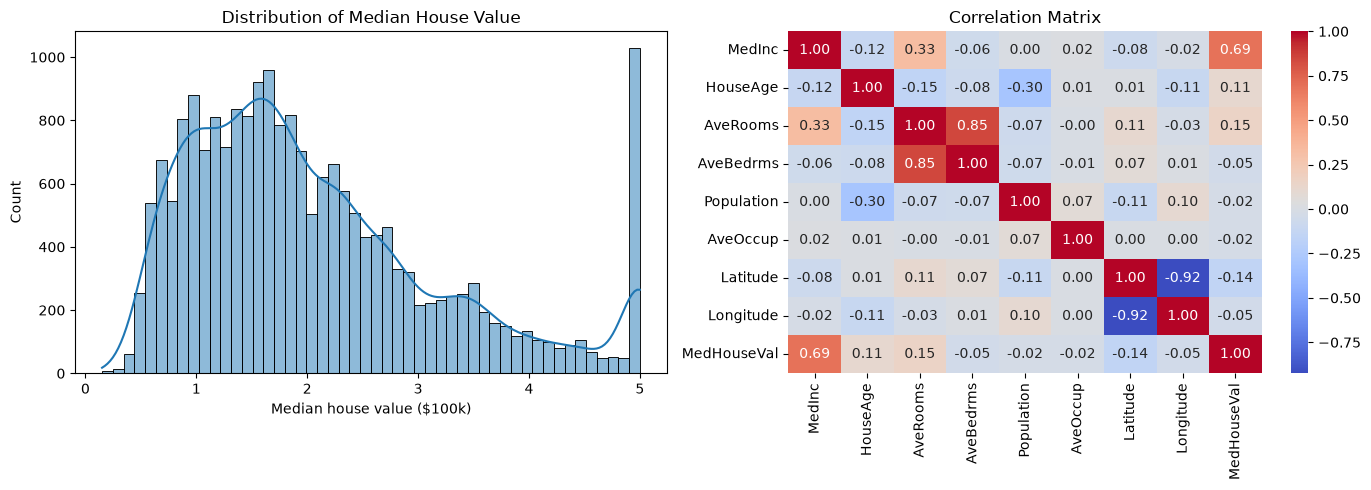

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["MedHouseVal"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Median House Value")
axes[0].set_xlabel("Median house value ($100k)")

sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [15]:
df_fe = df.copy()
df_fe["BedroomRatio"] = df_fe["AveBedrms"] / df_fe["AveRooms"]
df_fe["RoomsPerPerson"] = df_fe["AveRooms"] / df_fe["AveOccup"]
df_fe["LogPopulation"] = np.log1p(df_fe["Population"])

print(df_fe[["BedroomRatio", "RoomsPerPerson", "LogPopulation", "MedHouseVal"]]
      .corr()["MedHouseVal"].round(3))

BedroomRatio     -0.256
RoomsPerPerson    0.209
LogPopulation    -0.021
MedHouseVal       1.000
Name: MedHouseVal, dtype: float64


In [16]:
X = df_fe.drop(columns="MedHouseVal")
y = df_fe["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(16512, 11) (4128, 11)


In [17]:
alphas = np.logspace(-4, 2, 30)

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": RidgeCV(alphas=alphas, cv=5),
    "Lasso": LassoCV(alphas=alphas, cv=5, random_state=42, max_iter=10000),
}

for model in models.values():
    model.fit(X_train_s, y_train)

print("Best Ridge alpha:", round(models["Ridge"].alpha_, 4))
print("Best Lasso alpha:", round(models["Lasso"].alpha_, 4))

Best Ridge alpha: 62.1017
Best Lasso alpha: 0.0028


In [18]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test_s)
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

pd.DataFrame(rows).round(3)

,Model,MAE,RMSE,R2
0,Linear Regression,0.486,0.675,0.652
1,Ridge,0.486,0.676,0.651
2,Lasso,0.487,0.676,0.651


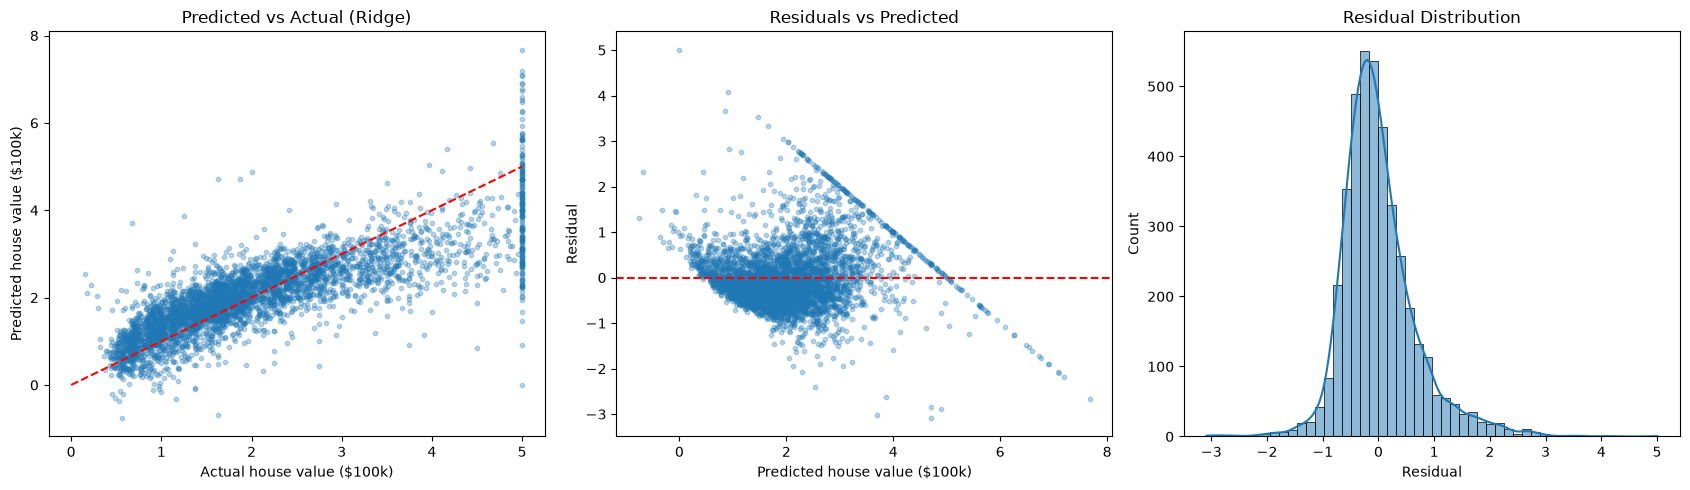

In [19]:
best_model = models["Ridge"]
pred = best_model.predict(X_test_s)
residuals = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_test, pred, alpha=0.3, s=10)
axes[0].plot([0, 5], [0, 5], "r--")
axes[0].set_title("Predicted vs Actual (Ridge)")
axes[0].set_xlabel("Actual house value ($100k)")
axes[0].set_ylabel("Predicted house value ($100k)")

axes[1].scatter(pred, residuals, alpha=0.3, s=10)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("Residuals vs Predicted")
axes[1].set_xlabel("Predicted house value ($100k)")
axes[1].set_ylabel("Residual")

sns.histplot(residuals, bins=50, kde=True, ax=axes[2])
axes[2].set_title("Residual Distribution")
axes[2].set_xlabel("Residual")

plt.tight_layout()
plt.show()

                Linear Regression  Ridge  Lasso
MedInc                      0.792  0.797  0.796
HouseAge                    0.130  0.134  0.130
AveRooms                   -0.146 -0.151 -0.151
AveBedrms                  -0.225 -0.215 -0.199
Population                  0.002  0.002  0.000
AveOccup                   -0.017 -0.018 -0.016
Latitude                   -0.880 -0.833 -0.843
Longitude                  -0.830 -0.783 -0.793
BedroomRatio                0.245  0.242  0.234
RoomsPerPerson              0.525  0.513  0.497
LogPopulation               0.040  0.040  0.037

Lasso coefficients set to zero: 1


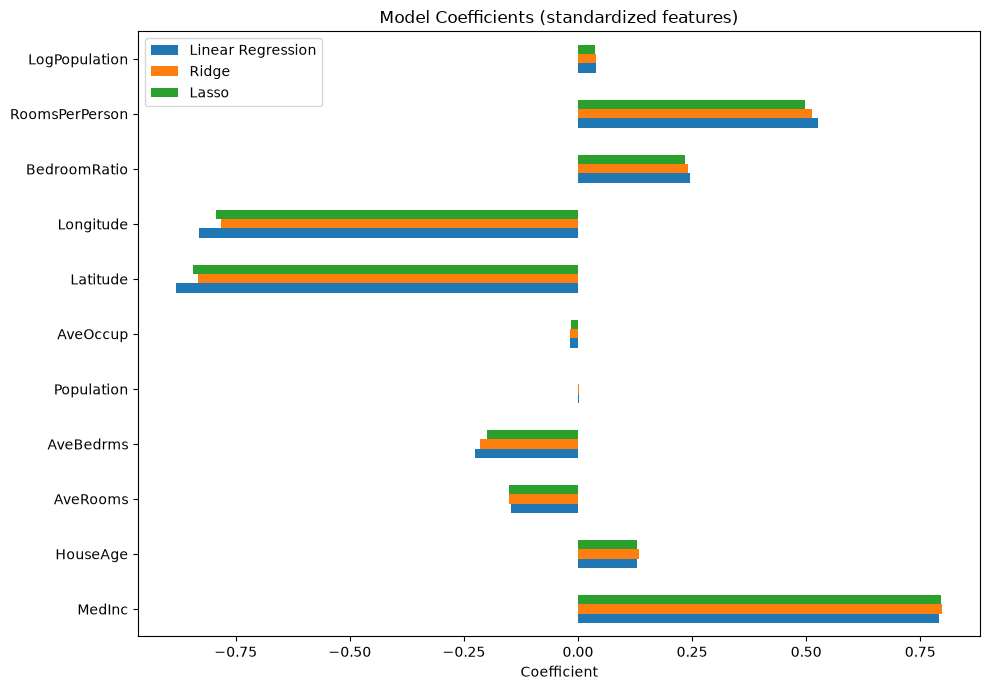

In [20]:
coef_df = pd.DataFrame({
    "Linear Regression": models["Linear Regression"].coef_,
    "Ridge": models["Ridge"].coef_,
    "Lasso": models["Lasso"].coef_,
}, index=X.columns).round(3)

print(coef_df)
print()
print("Lasso coefficients set to zero:", int((models["Lasso"].coef_ == 0).sum()))

coef_df.plot(kind="barh", figsize=(10, 7))
plt.title("Model Coefficients (standardized features)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

In [21]:
zeroed = X.columns[models["Lasso"].coef_ == 0].tolist()
print("Features removed by Lasso:", zeroed)
print("Best Ridge alpha:", round(models["Ridge"].alpha_, 4))
print("Best Lasso alpha:", round(models["Lasso"].alpha_, 4))

Features removed by Lasso: ['Population']
Best Ridge alpha: 62.1017
Best Lasso alpha: 0.0028


## Conclusions

- The California Housing dataset (20,640 samples, 8 original features, no missing values) was used to predict median house value. Three engineered features were added: BedroomRatio, RoomsPerPerson and LogPopulation.
- Median income (MedInc) is the feature most correlated with house value (0.69). The target is capped at $500k, which shows up as a spike at 5.0 in its distribution.
- Several features are strongly collinear (AveRooms/AveBedrms 0.85, Latitude/Longitude -0.92), which motivates regularized models.
- Linear Regression, Ridge and Lasso performed almost identically on the test set (R2 of about 0.65, MAE of about 0.49, i.e. roughly $49k average error). With 16,512 training samples and few features, regularization adds little.
- Ridge selected alpha = 62.10 and Lasso alpha = 0.0028 via 5-fold cross-validation. Lasso removed one feature, Population, which is redundant with the engineered LogPopulation feature.
- Possible next steps: tree-based models, interaction terms, or geographic features to capture the strong location effect.